# 02 — Video Exploration

Explores raw underwater **video files** — distinct from `01`, which explores frame-sequence *datasets* like BrackishMOT. This notebook is about footage that hasn't been split into annotated frames yet: container metadata, a handful of sampled frames, and per-frame quality signals (brightness, sharpness, color-channel balance) that `03_underwater_preprocessing.ipynb` will act on.

**Kernel:** **AquaTrack+ (.venv)**.

## Configuration

Set the video (or a directory of videos) here, once.

In [1]:
# --- Edit for your footage, then Run All -------------------------------
VIDEO_PATH = r"C:\Users\oyele\Downloads\C1304.MP4"
VIDEO_DIR = None  # set to a folder path to batch-scan every video in it instead
SAMPLE_COUNT = 8  # frames to sample for preview + quality metrics
# ------------------------------------------------------------------------

In [2]:
from pathlib import Path

video_path = Path(VIDEO_PATH)
assert video_path.is_file(), f"VIDEO_PATH does not exist or is not a file: {video_path}"
print(f"Exploring {video_path}")

Exploring C:\Users\oyele\Downloads\C1304.MP4


## Container metadata

In [3]:
from aquatrack.video import read_video_info

info = read_video_info(video_path)
minutes, seconds = divmod(info.duration_seconds, 60)
size_mb = info.file_size_bytes / (1024 * 1024)
print(f"resolution   : {info.width}x{info.height}")
print(f"fps          : {info.fps:.3f}")
print(f"frame count  : {info.frame_count}")
print(f"duration     : {int(minutes)}m {seconds:.1f}s")
print(f"codec (fourcc): {info.fourcc}")
print(f"file size    : {size_mb:.1f} MB")

resolution   : 3840x2160
fps          : 23.976
frame count  : 576
duration     : 0m 24.0s
codec (fourcc): h264
file size    : 284.0 MB


## Sample frames

Uniformly sampled across the clip (not just the first few seconds), since underwater footage often changes a lot with depth/turbidity over a single dive or drift.

In [4]:
from aquatrack.video import sample_frames

samples = sample_frames(video_path, count=SAMPLE_COUNT)
print(f"Sampled {len(samples)} frames at indices: {[i for i, _ in samples]}")

Sampled 8 frames at indices: [0, 82, 164, 246, 328, 410, 492, 575]


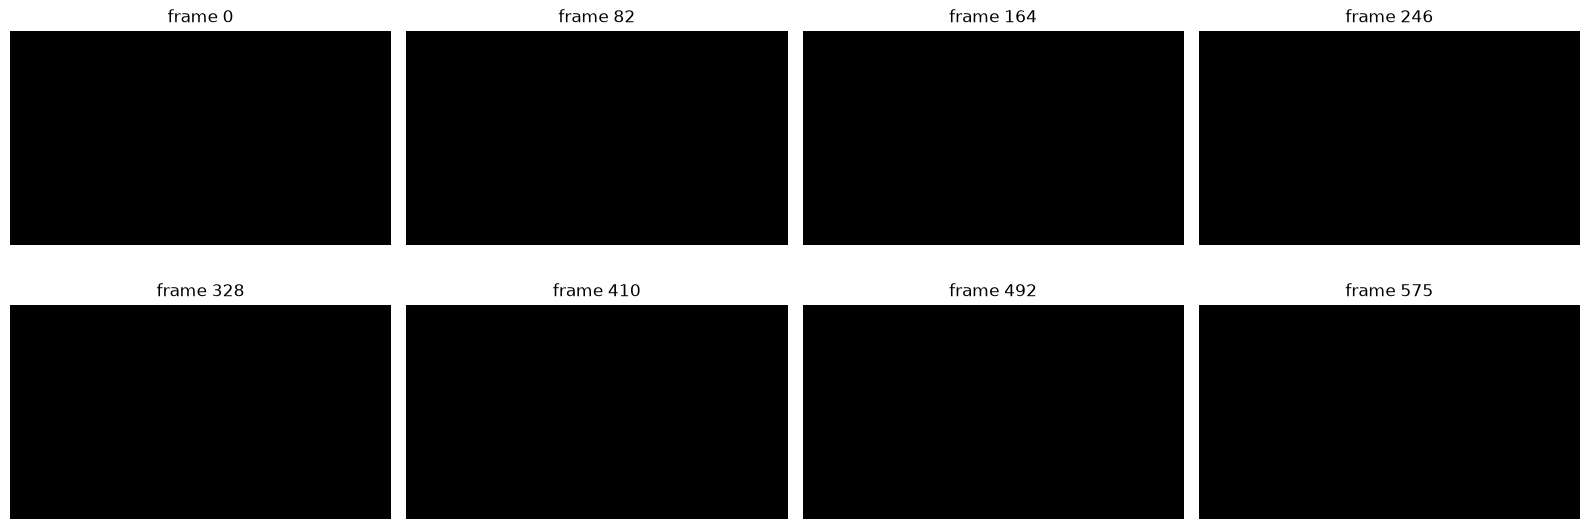

In [5]:
import cv2
import matplotlib.pyplot as plt

cols = min(4, len(samples))
rows = (len(samples) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))
axes = axes.flatten() if len(samples) > 1 else [axes]
for ax, (index, frame) in zip(axes, samples):
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {index}")
    ax.axis("off")
for ax in axes[len(samples):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Per-frame quality metrics

`red_deficiency` is `(blue + green) / 2 - red` — underwater footage loses red wavelengths first with depth/distance, so a large positive value here is a real, expected signal (not a bug), and quantifies how much color correction `03_underwater_preprocessing.ipynb` has to do.

In [6]:
import pandas as pd
from aquatrack.video import frame_quality_metrics

metrics_df = pd.DataFrame(
    [{"frame": index, **frame_quality_metrics(frame)} for index, frame in samples]
)
metrics_df

,frame,brightness,sharpness,blue_mean,green_mean,red_mean,red_deficiency
0,0,0.132530,1.727767,0.142917,0.095289,0.298423,-0.179320
1,82,0.138259,2.020123,0.161191,0.126095,0.174815,-0.031172
2,164,0.118895,1.918078,0.138565,0.108508,0.153518,-0.029981
3,246,0.135394,1.967892,0.154105,0.125238,0.167147,-0.027476
4,328,0.136362,1.992602,0.155312,0.126154,0.167785,-0.027052
5,410,0.116694,1.800752,0.130864,0.108906,0.146817,-0.026932
6,492,0.135797,1.960926,0.158267,0.124284,0.170893,-0.029617
7,575,0.118672,1.914778,0.140579,0.107854,0.154283,-0.030067


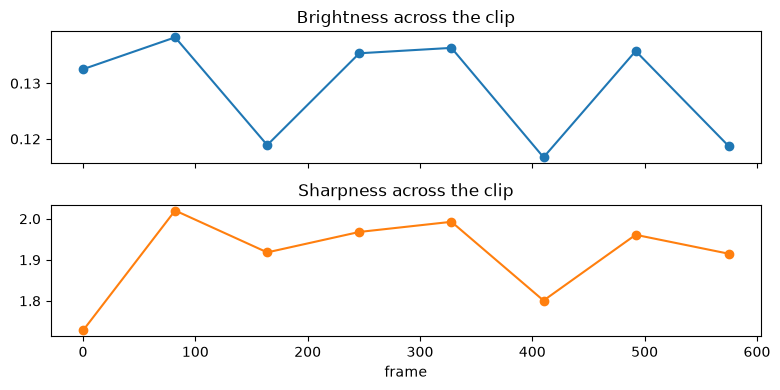

In [7]:
metrics_df.set_index("frame")[["brightness", "sharpness"]].plot(
    subplots=True, marker="o", figsize=(8, 4), legend=False,
    title=["Brightness across the clip", "Sharpness across the clip"],
)
plt.tight_layout()
plt.show()

### If brightness looks implausibly low (e.g. mean well under 20/255)

Check the source's color transfer characteristic before suspecting a decode bug:

```powershell
ffprobe -v error -select_streams v:0 -show_entries stream=pix_fmt,color_transfer,bits_per_raw_sample -of default=noprint_wrappers=1 <file>
```

`color_transfer=iec61966-2-4` (extended-gamut xvYCC) is a real, non-obvious cause: OpenCV/FFmpeg decode the raw YUV values correctly but do **not** apply that transfer curve, so the RGB you get back is genuinely dark/low-contrast compared to how the camera meant it to look. That's not corrupted data — it's exactly the kind of color-space correction `03_underwater_preprocessing.ipynb` needs to apply before detection, and this cell is how you'd catch it early instead of debugging a detector that mysteriously can't see anything.

## Optional: batch-scan a directory

Skipped unless `VIDEO_DIR` is set above — useful once there's more than one clip to triage (e.g. a full survey's worth of footage) before picking which ones to run through the rest of the pipeline.

In [8]:
from aquatrack.video import scan_video_directory

if VIDEO_DIR is not None:
    infos = scan_video_directory(VIDEO_DIR)
    batch_df = pd.DataFrame(
        [
            {
                "file": v.path.name,
                "duration_s": round(v.duration_seconds, 1),
                "fps": v.fps,
                "resolution": f"{v.width}x{v.height}",
                "codec": v.fourcc,
                "size_mb": round(v.file_size_bytes / (1024 * 1024), 1),
            }
            for v in infos
        ]
    )
    display(batch_df)
else:
    print("VIDEO_DIR not set — skipping batch scan.")

VIDEO_DIR not set — skipping batch scan.
